# 116 · Breakdowns (src9)

Standalone bar/heatmap functions over `score.per_sample` (now with `speaker`, `position_id`, mask centroids). Every plot takes `run`,
`speaker / box / objects / splits` filters where `None` = all; each bar carries its mean value and a ±1 std whisker clipped at 0 (no negative error cap).
Colours: **train** (grey), **id** (blue), **ood** (rose) in split-level plots; one fixed colour **per box** in box-level plots; sequential map for heatmaps.

**Scope:** plots 1–4 and 8 average over all speakers, and 1–4 over all boxes too (positions are shared, so averaging is free; box and speaker are
broken out only in 2 and 4, which are *about* them). Plots 5–7 fix one box — spatial grids and probe layouts differ per box (plastic for 5,
cardboard for 6/7) — and still average speakers; speaker 4 has no id splits, so it only appears via the unseen-speaker split in plot 4.

In [1]:
import sys, textwrap
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src9"))
import dataset as D9
import score

RUNS = ["t4-v1"]
SPLITS = [("train", None), ("one-object", "id"), ("two-object", "multiple"), ("unseen position", "unseen-position"),
          ("unseen rotation", "rotated"), ("unseen object", "unseen-object"), ("unseen weight", "cylinder"),
          ("unseen speaker", "unseen-speaker"), ("unseen speckles", "unseen-laser"), ("lid", "lid")]
BOXES = ["gastro", "plastic", "cardboard"]
THR = 0.08
CAT = {(b, s): c for b, cs in D9.CATEGORIES.items() for c, ss in cs.items() for s in ss}
ID_CATS = {"id", "multiple"}

# coherent, colourblind-safe, muted: three group hues + one darker hue per box + neutral ink
GROUP_COLOR = {"train": "#A0A7B0", "id": "#5B84B1", "ood": "#C28998"}
BOX_COLOR = {"gastro": "#5B84B1", "plastic": "#DE8F5F", "cardboard": "#6C9A6B"}
ALL_COLOR, EDGE, GRID = "#40464D", "#2A2E33", "#E3E3E3"

mpl.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.5, "axes.axisbelow": True,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "figure.dpi": 110})

In [2]:
ep = score.last_epoch(RUNS[-1])
DF, TRAIN_IOU = {}, {}

def object_of(s):
    return next((p for p in ("soap-dispenser", "portable-charger", "tomato-sauce", "coffee-pot", "two-cubes", "cube-vase",
                             "glass-cup", "cube", "vase", "candle", "cylinder", "biscoff") if s.startswith(p)), s)

for run in RUNS:
    df = score.per_sample(run, ep, THR)
    df["category"] = [CAT.get((b, s)) for b, s in zip(df.box, df.split)]
    df["object"] = df.split.map(object_of)
    df["weight"] = pd.to_numeric(df.split.str.extract(r"cylinder-(\d+)g")[0])
    DF[run] = df
    TRAIN_IOU[run] = float([l.rsplit(":", 1)[1] for l in (ROOT / "runs" / run / "logs-rank0.txt").read_text().splitlines()
                            if "metrics/train/iou08" in l][-1])
    print(f"{run}@{ep}ep: {len(df)} samples")

def pick(df, *, box=None, speaker=None, objects=None, splits=None, categories=None):
    m = pd.Series(True, index=df.index)
    if box is not None: m &= df.box == box
    if speaker is not None: m &= df.speaker == speaker
    if objects is not None: m &= df.object.isin([objects] if isinstance(objects, str) else objects)
    if splits is not None: m &= df.split.isin([splits] if isinstance(splits, str) else splits)
    if categories is not None: m &= df.category.isin(categories)
    return df[m]

def group(c):  # train / id / ood colour key for a category name
    return "train" if c is None else ("id" if c in ID_CATS else "ood")

def mstd(g):
    return (g.iou.mean() if len(g) else np.nan), (g.iou.std() if len(g) else 0.0)

def wrap(s, w=14):
    return "\n".join(textwrap.wrap(s, w)) if len(s) > w else s

def bar(ax, labels, mean, std, colors, title):
    x = np.arange(len(labels))
    mean, std = np.nan_to_num(np.asarray(mean, float)), np.nan_to_num(np.asarray(std, float))
    ax.bar(x, mean, yerr=np.minimum(std, mean), color=colors, edgecolor=EDGE, linewidth=0.5, capsize=2.5)
    for xi, v in zip(x, np.asarray(mean, float)):
        if np.isnan(v): continue
        ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", va="bottom", fontsize=8, fontweight="bold")
    ax.set_xticks(x, [wrap(l) for l in labels])
    ax.set_ylim(0, 1.08); ax.set_ylabel("IoU@0.08"); ax.set_title(title)

def heat(ax, mat, rows, cols, title, cmap="Blues"):
    mat, xfm, yfm = np.asarray(mat, float), np.arange(len(cols)), np.arange(len(rows))[::-1]
    m = np.ma.masked_invalid(mat[yfm][:, xfm])
    im = ax.imshow(m, cmap=cmap, vmin=0, vmax=1)
    off = len(rows) * 0 + 0.01
    for j, y in enumerate(yfm):
        for i, x in enumerate(xfm):
            if not m.mask[j, i]: ax.text(x, y, f"{m[j, i]:.2f}", ha="center", va="center", fontsize=8,
                                         fontweight="bold", color="white" if m[j, i] > .6 else "#333333")
    ax.set_xticks(xfm, [wrap(c) for c in cols]); ax.set_yticks(yfm, [wrap(r, 16) for r in rows])
    ax.grid(False); ax.set_title(title)
    return im

t4-v1@300ep: 4660 samples


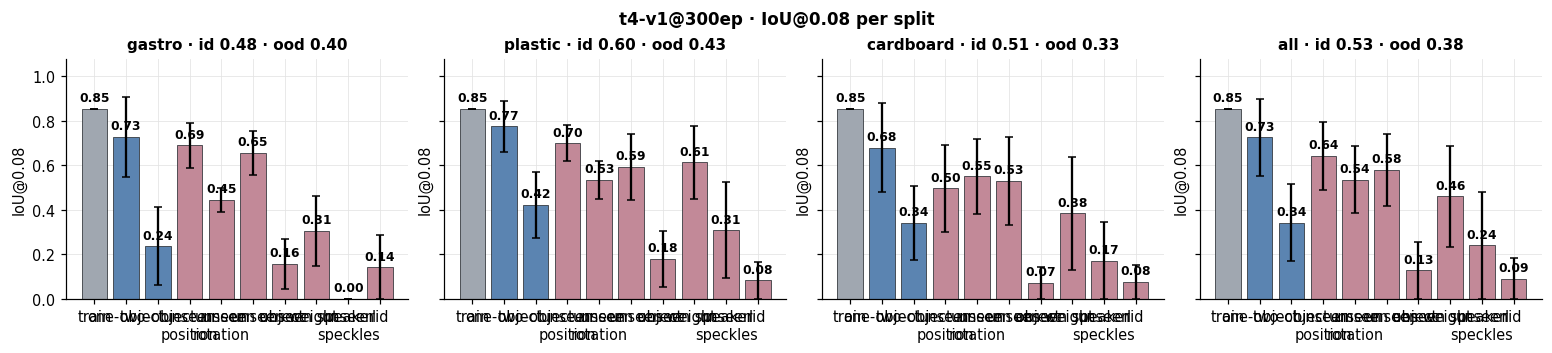

In [3]:
# 1 · IoU@0.08 per split; bars coloured by group (train / id / ood). run, speaker / box / objects filterable
def plot_by_split(run, *, box=None, speaker=None, objects=None):
    df = pick(DF[run], objects=objects)
    panels = (BOXES + ["all"]) if box is None else [box]
    fig, axes = plt.subplots(1, len(panels), figsize=(3.5 * len(panels), 3.1), constrained_layout=True, sharey=True)
    for ax, p in zip(np.atleast_1d(axes), panels):
        g = pick(df, box=p if p != "all" else None, speaker=speaker)
        labs, mean, std, colors = [], [], [], []
        for name, cat in SPLITS:
            if cat is None:
                m, s = (TRAIN_IOU[run], 0.0) if speaker is None else (np.nan, 0.0)
            else:
                m, s = mstd(g[g.category == cat])
            labs.append(name); mean.append(m); std.append(s); colors.append(GROUP_COLOR[group(cat)])
        bar(ax, labs, mean, std, colors, f"{p} · id {np.nanmean([m for m, (_, c) in zip(mean, SPLITS) if c in ID_CATS]):.2f}"
            f" · ood {np.nanmean([m for m, (_, c) in zip(mean, SPLITS) if c and c not in ID_CATS]):.2f}")
    fig.suptitle(f"{run}@{ep}ep · IoU@0.08 per split", fontsize=11, fontweight="bold")
    plt.show()

plot_by_split(RUNS[-1])

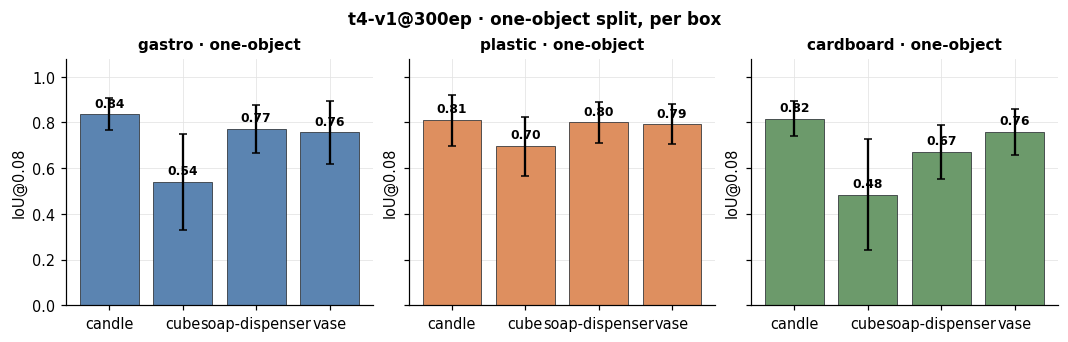

In [4]:
# 2 · one-object breakdown per box (bars = in-distribution objects, box colour). speaker / objects filterable
def plot_one_obj_by_box(run, *, box=None, speaker=None, objects=None):
    panels = BOXES if box is None else [box]
    fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.0), constrained_layout=True, sharey=True)
    for ax, b in zip(np.atleast_1d(axes), panels):
        g = pick(DF[run], box=b, speaker=speaker, categories={"id"})
        labs, mean, std = [], [], []
        for o in (sorted(g.object.unique()) if objects is None else objects):
            m, s = mstd(g[g.object == o]); labs.append(o); mean.append(m); std.append(s)
        bar(ax, labs, mean, std, [BOX_COLOR[b]] * len(labs), f"{b} · one-object")
    fig.suptitle(f"{run}@{ep}ep · one-object split, per box", fontsize=11, fontweight="bold")
    plt.show()

plot_one_obj_by_box(RUNS[-1])

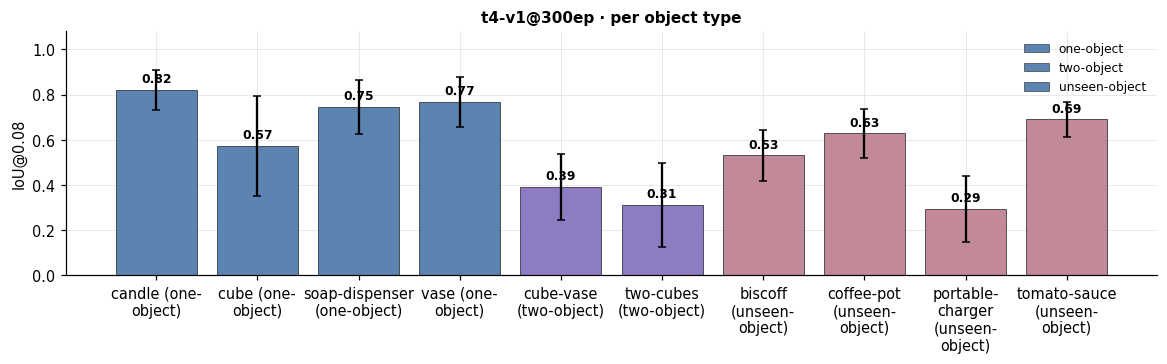

In [5]:
# 3 · per object type across the id categories, expanded: one bar per object, colour = one-object / two-object / unseen-object
def plot_by_object(run, *, box=None, speaker=None, objects=None):
    cats = [("one-object", "id"), ("two-object", "multiple"), ("unseen-object", "unseen-object")]
    CAT_COLOR = {"id": "#5B84B1", "multiple": "#8E7CC3", "unseen-object": "#C28998"}
    g = pick(DF[run], box=box, speaker=speaker)
    fig, ax = plt.subplots(figsize=(3 + 0.75 * sum(len(g[g.category == c].object.unique()) for _, c in cats), 3.2),
                           constrained_layout=True)
    labs, mean, std, colors, handles = [], [], [], [], []
    for name, cat in cats:
        for o in sorted(g[g.category == cat].object.unique()):
            if objects is not None and o not in objects: continue
            m, s = mstd(g[(g.category == cat) & (g.object == o)])
            if np.isnan(m): continue
            labs.append(f"{o}\n({name})"); mean.append(m); std.append(s); colors.append(CAT_COLOR[cat])
            handles.append(plt.Rectangle((0, 0), 1, 1, fc=CAT_COLOR[cat], ec=EDGE, lw=0.4))
    bar(ax, labs, mean, std, colors, f"{run}@{ep}ep · per object type")
    ax.legend(handles, [c for c, _ in cats], frameon=False, fontsize=8, loc="upper right")
    plt.show()

plot_by_object(RUNS[-1])

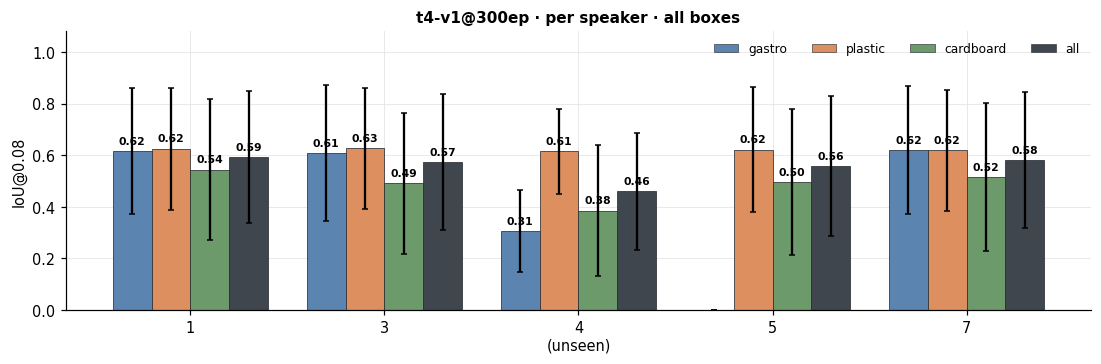

In [6]:
# 4 · per speaker (4 = unseen), grouped bars coloured by box (+ 'all'). run / box / objects filterable
def plot_by_speaker(run, *, box=None, objects=None):
    series = BOXES + ["all"] if box is None else [box]
    df = pick(DF[run], objects=objects)
    spks = sorted(df.speaker.unique())
    fig, ax = plt.subplots(figsize=(3 + 0.9 * len(spks) + 0.6 * len(series), 3.2), constrained_layout=True)
    x, w = np.arange(len(spks)), 0.8 / len(series)
    handles = []
    for i, s_ in enumerate(series):
        g = pick(df, box=s_ if s_ != "all" else None)
        mean = [g[g.speaker == k].iou.mean() for k in spks]
        std = [g[g.speaker == k].iou.std() for k in spks]
        pos = x + (i - (len(series) - 1) / 2) * w
        ax.bar(pos, np.nan_to_num(mean), w, yerr=np.minimum(np.nan_to_num(std), np.nan_to_num(mean)),
               color=BOX_COLOR.get(s_, ALL_COLOR), edgecolor=EDGE, linewidth=0.5, capsize=2)
        for xi, v in zip(pos, np.asarray(mean, float)):
            if np.isnan(v): continue
            ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", va="bottom", fontsize=7, fontweight="bold")
        handles.append(plt.Rectangle((0, 0), 1, 1, fc=BOX_COLOR.get(s_, ALL_COLOR), ec=EDGE, lw=0.4))
    ax.set_xticks(x, [f"{k}\n(unseen)" if k == 4 else str(k) for k in spks])
    ax.set_ylim(0, 1.08); ax.set_ylabel("IoU@0.08")
    ax.set_title(f"{run}@{ep}ep · per speaker" + (f" · box: {box}" if box else " · all boxes") +
                 (f" · objects: {objects}" if objects else ""))
    ax.legend(handles, series, frameon=False, fontsize=8, loc="upper right", ncol=min(len(series), 4))
    plt.show()

plot_by_speaker(RUNS[-1])

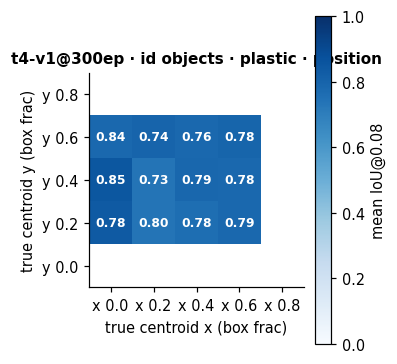

In [7]:
# 5 · position-in-box heatmap (default plastic), id objects, speaker-averaged: value = mean IoU of the bin, bins
#     located by the true mask centroid. rows/cols/bins override; box can be any box or None (pooled, no 'geo' meaning)
def plot_position_heatmap(run, *, box="plastic", speaker=None, objects=None, bins=5):
    g = pick(DF[run], box=box, speaker=speaker, categories={"id"}, objects=objects)
    cy, cx, val = g.cy.values, g.cx.values, g.iou.values
    ok = ~(np.isnan(cy) | np.isnan(cx))
    cy, cx, val = cy[ok], cx[ok], val[ok]
    n = np.histogram2d(cy, cx, bins=bins, range=[[0, 1], [0, 1]])[0]
    s = np.histogram2d(cy, cx, bins=bins, range=[[0, 1], [0, 1]], weights=val)[0]
    mat = np.where(n > 0, s / np.maximum(n, 1), np.nan)
    fig, ax = plt.subplots(figsize=(3.4, 3.2), constrained_layout=True)
    im = heat(ax, mat, [f"y {i/(bins)}" for i in range(bins)], [f"x {i/(bins)}" for i in range(bins)],
              f"{run}@{ep}ep · id objects · {box if box else 'all boxes'} · position")
    ax.set_xlabel("true centroid x (box frac)"); ax.set_ylabel("true centroid y (box frac)")
    fig.colorbar(im, ax=ax, label="mean IoU@0.08")
    plt.show()

plot_position_heatmap(RUNS[-1])

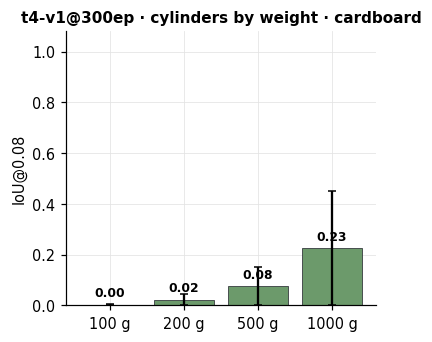

In [8]:
# 6 · cylinders by weight in the cardboard box (speaker-averaged). run / box / speaker filterable
def plot_by_weight(run, *, box="cardboard", speaker=None):
    g = pick(DF[run], box=box, speaker=speaker, categories={"cylinder"} if box else None, objects="cylinder")
    labs, mean, std = [], [], []
    for w_ in sorted(g.weight.dropna().unique()):
        m, s = mstd(g[g.weight == w_]); labs.append(f"{w_:.0f} g"); mean.append(m); std.append(s)
    fig, ax = plt.subplots(figsize=(3.4, 3.0), constrained_layout=True)
    bar(ax, labs, mean, std, [BOX_COLOR.get(box, ALL_COLOR)] * len(labs), f"{run}@{ep}ep · cylinders by weight · {box}")
    plt.show()

plot_by_weight(RUNS[-1])

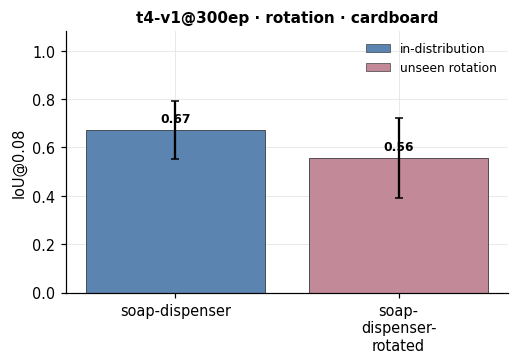

In [9]:
# 7 · rotation in the cardboard box (speaker-averaged): id soap-dispenser orientations vs rotated variants
def plot_by_rotation(run, *, box="cardboard", speaker=None, objects=("soap-dispenser",)):
    g = pick(DF[run], box=box, speaker=speaker, objects=objects)
    order = [s for s in sorted(g.split.unique()) if not any(k in s for k in ("angle", "laser", "unseen"))]
    labs, mean, std, colors = [], [], [], []
    for s_ in order:
        m, t = mstd(g[g.split == s_])
        if np.isnan(m): continue
        rot = any(k in s_ for k in ("rotated", "sideways"))
        labs.append(s_); mean.append(m); std.append(t); colors.append(GROUP_COLOR["ood" if rot else "id"])
    fig, ax = plt.subplots(figsize=(3 + 0.8 * len(labs), 3.2), constrained_layout=True)
    bar(ax, labs, mean, std, colors, f"{run}@{ep}ep · rotation · {box}")
    ax.legend([plt.Rectangle((0, 0), 1, 1, fc=GROUP_COLOR[k], ec=EDGE, lw=0.4) for k in ("id", "ood")],
              ["in-distribution", "unseen rotation"], frameon=False, fontsize=8, loc="upper right")
    plt.show()

plot_by_rotation(RUNS[-1])

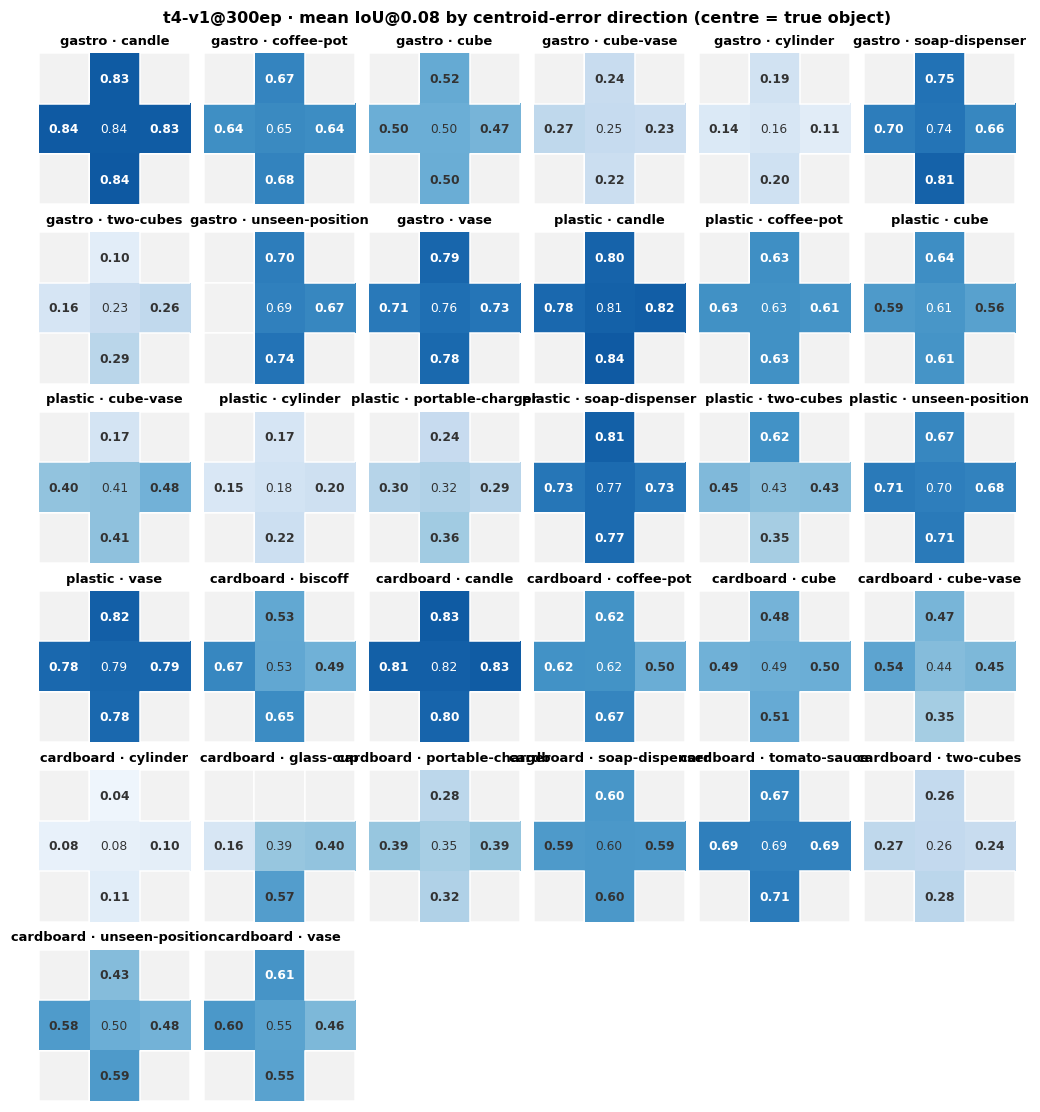

In [10]:
# 8 · centroid-direction maps: one 3x3 cell grid per box×object — centre = the true object with its overall mean
#     IoU, the 4 cardinal cells show the mean IoU of samples whose pred-centroid error points that way
#     (↑ = pred above true, …), diagonals unused. speaker-averaged
def plot_by_direction(run, *, speaker=None, boxes=None, objects=None):
    df = pick(DF[run], speaker=speaker)
    boxes = boxes or BOXES
    combos = [(b, o) for b in boxes for o in sorted(df[df.box == b].object.unique())
              if objects is None or o in objects]
    ncol = min(len(combos), 6)
    nrow = int(np.ceil(len(combos) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(1.5 * ncol, 1.6 * nrow + 0.4), constrained_layout=True)
    for ax, (b, o) in zip(np.atleast_1d(axes).ravel(), combos):
        g = df[(df.box == b) & (df.object == o)].dropna(subset=["cx", "pred_cx", "cy", "pred_cy"])
        dx, dy = (g.pred_cx - g.cx).values, (g.pred_cy - g.cy).values
        card = {"left": [(dx < 0) & (np.abs(dx) >= np.abs(dy))], "right": [(dx > 0) & (np.abs(dx) >= np.abs(dy))],
                "up": [(dy < 0) & (np.abs(dy) > np.abs(dx))], "down": [(dy > 0) & (np.abs(dy) > np.abs(dx))]}
        mat = np.full((3, 3), np.nan)
        mat[1, 1] = g.iou.mean()
        for name, (m,) in card.items():
            r, c = {"up": (0, 1), "down": (2, 1), "left": (1, 0), "right": (1, 2)}[name]
            if m.any(): mat[r, c] = g.iou.values[m].mean()
        m = np.ma.masked_invalid(mat)
        im = ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
        for r in range(3):
            for c in range(3):
                if not m.mask[r, c]:
                    v = m[r, c]
                    is_card = (r, c) != (1, 1)
                    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8,
                            fontweight="bold" if is_card else "normal",
                            color="white" if v > 0.6 else "#333333")
                else:
                    ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fc="#F2F2F2", ec="white", lw=1))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"{b} · {o}", fontsize=8.5)
        for sp in ax.spines.values(): sp.set_visible(False)
    for ax in np.atleast_1d(axes).ravel()[len(combos):]: ax.axis("off")
    fig.suptitle(f"{run}@{ep}ep · mean IoU@0.08 by centroid-error direction (centre = true object)", fontsize=10.5, fontweight="bold")
    plt.show()

plot_by_direction(RUNS[-1])